In [123]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [124]:
data = {
    'cgpa': [
        5.2, 6.1, 7.4, 8.8, 9.2, 6.5, 7.8, 8.1, 5.9, 9.5,
        6.8, 7.2, 8.5, 5.5, 9.0, 7.6, 6.3, 8.9, 7.1, 9.7,
        5.8, 8.2, 6.9, 7.9, 9.3, 6.0, 8.6, 7.3, 5.4, 8.4
    ],
    'profile_score': [
        55, 62, 78, 88, 92, 85, 72, 80, 60, 96,
        78, 68, 90, 50, 94, 75, 65, 89, 70, 98,
        58, 83, 76, 81, 95, 63, 91, 73, 52, 86
    ],
    'job': [
        0, 0, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
        0, 1, 0, 1, 1, 0, 1, 0, 0, 1
    ]
}

df = pd.DataFrame(data)
X = df[['cgpa', 'profile_score']].values
Y=df[['job']].values

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [125]:
def initzialise_parameter():
    np.random.seed(1)
    W=np.random.randn(2,1)*0.01
    B=np.zeros((1,1))
    return W,B

In [ ]:
def forward_propagation(X,W,B):
    
    Z=np.dot(X,W)+B

    # sigmoid activation function
    A=1/(1+np.exp(-Z))
    return A

In [ ]:
def backward_propagation(Y_pred,Y,X):
    m = X.shape[0]
    
    #loss function
    loss = -np.mean(
            Y * np.log(Y_pred + 1e-8) +
            (1 - Y) * np.log(1 - Y_pred + 1e-8)
        )
    #gardient descent 
    dZ = Y_pred - Y
    dW = np.dot(X.T, dZ) / m
    db = np.sum(dZ) / m

    return dW,db,loss

In [ ]:
def perceptron(epochs):
    W, B = initzialise_parameter()
    learning_rate = 0.01
    loss_history = []

    for i in range(epochs):

        Y_pred = forward_propagation(X, W, B)
        
        dW,db,loss= backward_propagation(Y_pred, Y, X)

        loss_history.append(loss)

        W = W - learning_rate * dW
        B = B - learning_rate * db

    return loss_history

In [129]:
epochs=1000
loss_history = perceptron(epochs)
for epoch in range(epochs):
    if epoch % 100 == 0:
            print(f"Epoch {epoch}, Loss: {loss_history[epoch]:.4f}")

Epoch 0, Loss: 0.6889
Epoch 100, Loss: 0.4793
Epoch 200, Loss: 0.3863
Epoch 300, Loss: 0.3360
Epoch 400, Loss: 0.3046
Epoch 500, Loss: 0.2829
Epoch 600, Loss: 0.2670
Epoch 700, Loss: 0.2548
Epoch 800, Loss: 0.2450
Epoch 900, Loss: 0.2369


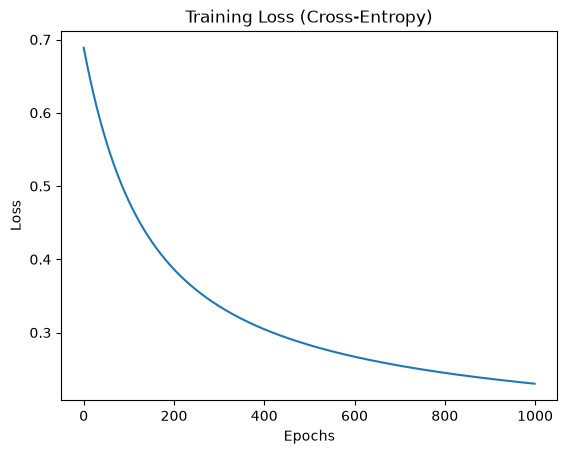

In [130]:
plt.plot(loss_history)
plt.title("Training Loss (Cross-Entropy)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()